# Los Ninos Modelling Phase

The **aim** of this notebook is to come up with a model that can predict whether a Kenyan county will flood next month using these conditions: Rain, Vegetation, Soil, Rivers, Ocean Climate, and fixed county facts.

**DATA:**
1) Train.csv - Data from 2002-2019
2) Test.csv - Data from 2020-2024
3) Model_table.csv - Combined table

**PLAN:**
Start with a baseline and a very simple Logistic Regression model, then check whether the stronger models (Random Forest & XGBoost) can actually beat them.

## Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, average_precision_score


## Loading the data and checking if they fit together

In [ ]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
main = pd.read_csv("model_table.csv")

print(f"Train: {train.shape} | Train Years: {train.year.min()} - {train.year.max()}")
print(f"Test: {test.shape} | Test Years: {test.year.min()} - {test.year.max()}")
print(f"Main: {main.shape}")
print(f"Overlapping rows between our Train and Test values: {len(train.merge(test, on= ['pcode', 'year', 'month']))}")
print(f"Blank rows: {int(train.isna().sum().sum()) + int(test.isna().sum().sum())}")


Train: (9870, 30) | Train Years: 2002 - 2019
Test: (2820, 30) | Test Years: 2020 - 2024
Main: (12690, 30)
Overlapping rows between our Train and Test values: 0
Blank rows: 0


## Splitting into features and targets

In [ ]:
not_features = ['pcode', 'year', 'month', 'county', 'flood_next_month', 'flood_this_month']
X_train = train.drop(not_features, axis= 1)
y_train = train['flood_next_month']
X_test = test.drop(not_features, axis= 1)
y_test = test['flood_next_month']

print(X_train.shape)

(9870, 24)


## Training our models and evaluating its performance

In [ ]:
scores = {}

month_rate = train.groupby("month").flood_next_month.mean()
scores['calendar_baseline'] = test['month'].map(month_rate).to_numpy()

model = make_pipeline(SimpleImputer(strategy= 'median'), StandardScaler(), LogisticRegression(max_iter= 1000, class_weight= 'balanced', C= 1))
model.fit(X_train, y_train)
scores['logistic_regression'] = model.predict_proba(X_test)[:, 1]

print(f"Trained: {list(scores)}")

Trained: ['calendar_baseline', 'logistic_regression']


In [ ]:
y_pred_test = model.predict(X_test)

confusion = confusion_matrix(y_test, y_pred_test)

tn, fp, fn, tp = confusion.ravel()

print(f"F1 score: {2*tp/(2*tp + fp + fn):.2f}")
print(f"Accuracy score: {(tp + tn)/(tp + tn + fp + fn):.2f}")
print(f"Precision score: {tp/(tp + fp):.2f}")
print(f"Recall score: {tp/(tp + fn):.2f}")
print(f"ROC-AUC score: {roc_auc_score(y_test, y_pred_test):.2f}")
print('\n', classification_report(y_test, y_pred_test, target_names= ['No flood', 'Flood']))

F1 score: 0.20
Accuracy score: 0.67
Precision score: 0.11
Recall score: 0.81
ROC-AUC score: 0.73

               precision    recall  f1-score   support

    No flood       0.98      0.66      0.79      2676
       Flood       0.11      0.81      0.20       144

    accuracy                           0.67      2820
   macro avg       0.55      0.73      0.49      2820
weighted avg       0.94      0.67      0.76      2820



## Random Forest Classifier and XGBoost modelling

### Building, training and evaluating a Random Forest model

In [ ]:
rf = RandomForestClassifier(
    n_estimators = 300,
    max_depth = 8,
    min_samples_leaf = 20,
    class_weight = 'balanced',
    random_state = 42
)

rf.fit(X_train, y_train)
scores['random_forest'] = rf.predict_proba(X_test)[:, 1]
print(f"Trained: {list(scores)}")

Trained: ['calendar_baseline', 'logistic_regression', 'random_forest']


In [ ]:
y_pred_test_rf = rf.predict(X_test)

confusion = confusion_matrix(y_test, y_pred_test_rf)

tn, fp, fn, tp = confusion.ravel()

print(f"F1 score: {2*tp/(2*tp + fp + fn):.2f}")
print(f"Accuracy score: {(tp + tn)/(tp + tn + fp + fn):.2f}")
print(f"Precision score: {tp/(tp + fp):.2f}")
print(f"Recall score: {tp/(tp + fn):.2f}")
print(f"ROC-AUC score: {roc_auc_score(y_test, y_pred_test_rf):.2f}")
print('\n', classification_report(y_test, y_pred_test_rf, target_names= ['No flood', 'Flood']))

F1 score: 0.23
Accuracy score: 0.79
Precision score: 0.14
Recall score: 0.63
ROC-AUC score: 0.71

               precision    recall  f1-score   support

    No flood       0.98      0.80      0.88      2676
       Flood       0.14      0.63      0.23       144

    accuracy                           0.79      2820
   macro avg       0.56      0.71      0.55      2820
weighted avg       0.93      0.79      0.84      2820



### Building, Training and Evaluating a XGBoost Model

In [ ]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators = 300,
    max_depth = 3,
    learning_rate = 0.03,
    scale_pos_weight = ratio,
    random_state = 42
)

xgb.fit(X_train, y_train)
scores['XGB_boost'] = xgb.predict_proba(X_test)[:, 1]
print(f"Trained: {list(scores)}")

Trained: ['calendar_baseline', 'logistic_regression', 'random_forest', 'XGB_boost']


In [ ]:
y_pred_test_xgb = xgb.predict(X_test)

confusion = confusion_matrix(y_test, y_pred_test_xgb)

tn, fp, fn, tp = confusion.ravel()

print(f"F1 score: {2*tp/(2*tp + fp + fn):.2f}")
print(f"Accuracy score: {(tp + tn)/(tp + tn + fp + fn):.2f}")
print(f"Precision score: {tp/(tp + fp):.2f}")
print(f"Recall score: {tp/(tp + fn):.2f}")
print(f"ROC-AUC score: {roc_auc_score(y_test, y_pred_test_xgb):.2f}")
print('\n', classification_report(y_test, y_pred_test_xgb, target_names= ['No flood', 'Flood']))

F1 score: 0.21
Accuracy score: 0.75
Precision score: 0.13
Recall score: 0.68
ROC-AUC score: 0.71

               precision    recall  f1-score   support

    No flood       0.98      0.75      0.85      2676
       Flood       0.13      0.68      0.21       144

    accuracy                           0.75      2820
   macro avg       0.55      0.71      0.53      2820
weighted avg       0.93      0.75      0.82      2820



## Getting feature importances

In [ ]:
importances = pd.DataFrame({
    "random_forest" : rf.feature_importances_,
    "XGB_boost" : xgb.feature_importances_
}, index= X_train.columns)

print(f"Important features for Random Forest: \n {importances.sort_values("random_forest", ascending= False).round(3).head(5)}")
print(f"Important features for XGB Boost: \n {importances.sort_values("XGB_boost", ascending= False).round(3).head(5)}")

Important features for Random Forest: 
                    random_forest  XGB_boost
dmi                        0.114      0.074
neighbour_rain             0.108      0.089
oni                        0.098      0.061
county_flood_rate          0.092      0.135
rain_mm                    0.057      0.028
Important features for XGB Boost: 
                    random_forest  XGB_boost
county_flood_rate          0.092      0.135
neighbour_rain             0.108      0.089
dmi                        0.114      0.074
month_sin                  0.054      0.074
month_cos                  0.041      0.069


### Visualizing our results

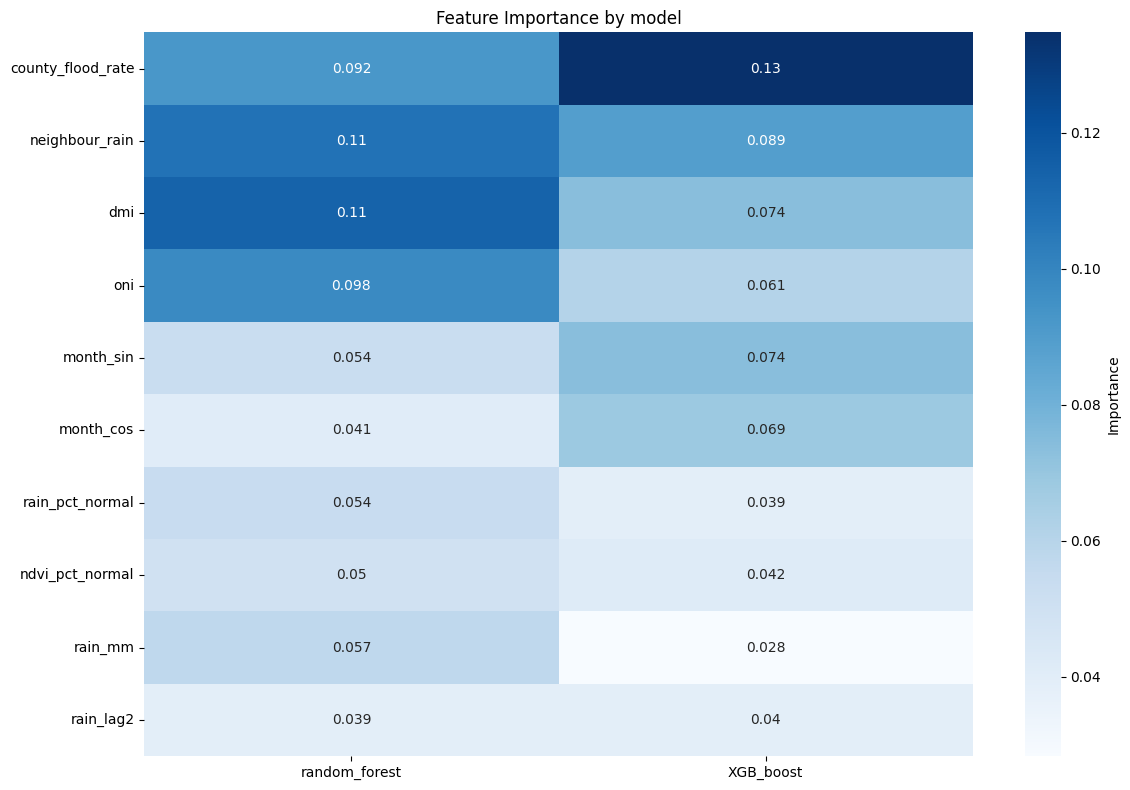

In [ ]:
top_features = 10
order = importances.mean(axis= 1).sort_values(ascending= False).head(top_features).index

plt.figure(figsize=(12, 8))
sns.heatmap(importances.loc[order], annot= True, cmap= "Blues", cbar_kws= {"label": "Importance"})
plt.title("Feature Importance by model")
plt.tight_layout()
plt.show()

## Comparing our models performances

In [ ]:
rows = []

for names, j in scores.items():
  rows.append({
      "Model": names,
      "ROC-AUC": roc_auc_score(y_test, j),
      "PR_AUC": average_precision_score(y_test, j)
  })

  results = pd.DataFrame(rows).set_index("Model").round(3)

In [ ]:
results

,ROC-AUC,PR_AUC
Model,,
calendar_baseline,0.762,0.141
logistic_regression,0.807,0.177
random_forest,0.798,0.183
XGB_boost,0.792,0.151


## OBSERVATIONS

- In our test set, only 144 rows out of 2820 rows were floods (about 5%), this means we are trying to predict a very rare event.

- Logistic Regression performed best at ranking risk overall (ROC_AUC) and beats the baseline record, proving that weather/vegetation/ocean features are adding real predictive value beyond just "what month is it".

- Random Forest however, has the best PR_AUC score, meaning that it will be able to catch the most dangerous floods and will return the fewest false alarms.

- XGBoost was the worst performed model especially when it's supposed to shine in complex projects, meaning that our simpler models were more robust and the data we had wasn't enough to feed XGBoost's complexity.

- The low influence of our current features suggests a possible gap in our feature engineering; identifying the missing variable(s) will be essential to improving model performance.

## SMALL CHANGE

**Adding Flood this month as a feature**

- "flood_this_month" is already in the table, but wasn't marked as a feature. A county that flooded this month and/or last month is more likely to flood next month. So our idea is to add flood_this_month as a feature and come up with "flood_last_month" values by shifting our current month answers down my a row so that every month for each county has a "last month" clue next to it.

**Why include these?**
- The main goal of the model is to predict what is going to happen next month. Our new clues are in the past, so the model isn't peeking at the answer. Essentially, a clue is something you know before you guess, and the answer is what we're trying to guess. In this case, "flood_last_month" were answers for before, "flood_this_month" is an answer for **NOW**, but since we are looking at predicting floods for next month, it can be used as a clue (feature).

So let's redo the entire modelling process and compare our results.

In [ ]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
main = pd.read_csv("model_table.csv")

print(f"Train: {train.shape} | Train Years: {train.year.min()} - {train.year.max()}")
print(f"Test: {test.shape} | Test Years: {test.year.min()} - {test.year.max()}")
print(f"Main: {main.shape}")
print(f"Overlapping rows between our Train and Test values: {len(train.merge(test, on= ['pcode', 'year', 'month']))}")
print(f"Blank rows: {int(train.isna().sum().sum()) + int(test.isna().sum().sum())}")


Train: (9870, 30) | Train Years: 2002 - 2019
Test: (2820, 30) | Test Years: 2020 - 2024
Main: (12690, 30)
Overlapping rows between our Train and Test values: 0
Blank rows: 0


In [ ]:
not_features = ['pcode', 'year', 'month', 'county', 'flood_next_month', 'flood_this_month']
X_train = train.drop(not_features, axis= 1)
y_train = train['flood_next_month']
X_test = test.drop(not_features, axis= 1)
y_test = test['flood_next_month']

print(X_train.shape)

(9870, 24)


## Implementing our hypothesis

In [ ]:
all_rows = pd.concat([train, test], keys= ["train", "test"]) # Stacks the two tables into one so that it's simpler to look back on the previous months (which some might end up on the training set)
last_month = all_rows.groupby("pcode")["flood_this_month"].shift(1).fillna(0) # Building the flood last month for each county.

X_train["flood_this_month"] = train["flood_this_month"].values # Copying our values since we dropped it earlier
X_test["flood_this_month"] = test["flood_this_month"].values
X_train["flood_last_month"] = last_month.loc["train"].values # Takes only the training values for the "last_month"
X_test["flood_last_month"] = last_month.loc["test"].values # Takes only the testing values for the "last_month"

print(X_train.shape)

(9870, 26)


## Re-train our models

**Logistic Regression**

In [ ]:
model_2 = make_pipeline(SimpleImputer(strategy= 'median'), StandardScaler(), LogisticRegression(max_iter= 1000, class_weight= 'balanced', C= 1))
model_2.fit(X_train, y_train)
scores['logistic_regression_2'] = model_2.predict_proba(X_test)[:, 1]

print(f"Trained: {list(scores)}")

Trained: ['calendar_baseline', 'logistic_regression', 'random_forest', 'XGB_boost', 'logistic_regression_2']


In [ ]:
y_pred_test_lr2 = model_2.predict(X_test)

confusion = confusion_matrix(y_test, y_pred_test_lr2)

tn, fp, fn, tp = confusion.ravel()

print(f"F1 score: {2*tp/(2*tp + fp + fn):.2f}")
print(f"Accuracy score: {(tp + tn)/(tp + tn + fp + fn):.2f}")
print(f"Precision score: {tp/(tp + fp):.2f}")
print(f"Recall score: {tp/(tp + fn):.2f}")
print(f"ROC-AUC score: {roc_auc_score(y_test, y_pred_test_lr2):.2f}")
print('\n', classification_report(y_test, y_pred_test_lr2, target_names= ['No flood', 'Flood']))

F1 score: 0.27
Accuracy score: 0.78
Precision score: 0.16
Recall score: 0.78
ROC-AUC score: 0.78

               precision    recall  f1-score   support

    No flood       0.98      0.78      0.87      2676
       Flood       0.16      0.78      0.27       144

    accuracy                           0.78      2820
   macro avg       0.57      0.78      0.57      2820
weighted avg       0.94      0.78      0.84      2820



**Random Forest Classifier**

In [ ]:
rf_2 = RandomForestClassifier(
    n_estimators = 300,
    max_depth = 8,
    min_samples_leaf = 20,
    class_weight = 'balanced',
    random_state = 42
)

rf_2.fit(X_train, y_train)
scores['random_forest_2'] = rf_2.predict_proba(X_test)[:, 1]
print(f"Trained: {list(scores)}")

Trained: ['calendar_baseline', 'logistic_regression', 'random_forest', 'XGB_boost', 'logistic_regression_2', 'random_forest_2']


In [ ]:
y_pred_test_rf2 = rf_2.predict(X_test)

confusion = confusion_matrix(y_test, y_pred_test_rf2)

tn, fp, fn, tp = confusion.ravel()

print(f"F1 score: {2*tp/(2*tp + fp + fn):.2f}")
print(f"Accuracy score: {(tp + tn)/(tp + tn + fp + fn):.2f}")
print(f"Precision score: {tp/(tp + fp):.2f}")
print(f"Recall score: {tp/(tp + fn):.2f}")
print(f"ROC-AUC score: {roc_auc_score(y_test, y_pred_test_rf2):.2f}")
print('\n', classification_report(y_test, y_pred_test_rf2, target_names= ['No flood', 'Flood']))

F1 score: 0.33
Accuracy score: 0.86
Precision score: 0.22
Recall score: 0.69
ROC-AUC score: 0.78

               precision    recall  f1-score   support

    No flood       0.98      0.86      0.92      2676
       Flood       0.22      0.69      0.33       144

    accuracy                           0.86      2820
   macro avg       0.60      0.78      0.62      2820
weighted avg       0.94      0.86      0.89      2820



**XGBoost**

In [ ]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb_2 = XGBClassifier(
    n_estimators = 300,
    max_depth = 3,
    learning_rate = 0.03,
    scale_pos_weight = ratio,
    random_state = 42
)

xgb_2.fit(X_train, y_train)
scores['XGB_boost_2'] = xgb_2.predict_proba(X_test)[:, 1]
print(f"Trained: {list(scores)}")

Trained: ['calendar_baseline', 'logistic_regression', 'random_forest', 'XGB_boost', 'logistic_regression_2', 'random_forest_2', 'XGB_boost_2']


In [ ]:
y_pred_test_xgb2 = xgb_2.predict(X_test)

confusion = confusion_matrix(y_test, y_pred_test_xgb2)

tn, fp, fn, tp = confusion.ravel()

print(f"F1 score: {2*tp/(2*tp + fp + fn):.2f}")
print(f"Accuracy score: {(tp + tn)/(tp + tn + fp + fn):.2f}")
print(f"Precision score: {tp/(tp + fp):.2f}")
print(f"Recall score: {tp/(tp + fn):.2f}")
print(f"ROC-AUC score: {roc_auc_score(y_test, y_pred_test_xgb2):.2f}")
print('\n', classification_report(y_test, y_pred_test_xgb2, target_names= ['No flood', 'Flood']))

F1 score: 0.32
Accuracy score: 0.84
Precision score: 0.20
Recall score: 0.72
ROC-AUC score: 0.78

               precision    recall  f1-score   support

    No flood       0.98      0.85      0.91      2676
       Flood       0.20      0.72      0.32       144

    accuracy                           0.84      2820
   macro avg       0.59      0.78      0.61      2820
weighted avg       0.94      0.84      0.88      2820



## Displaying our results

In [ ]:
rows = []

for names, k in scores.items():
  rows.append({
      "Model": names,
      "ROC-AUC": roc_auc_score(y_test, k),
      "PR-AUC": average_precision_score(y_test, k)
  })

  results = pd.DataFrame(rows).set_index("Model").round(3)
results

,ROC-AUC,PR-AUC
Model,,
calendar_baseline,0.762,0.141
logistic_regression,0.807,0.177
random_forest,0.798,0.183
XGB_boost,0.792,0.151
logistic_regression_2,0.873,0.374
random_forest_2,0.888,0.376
XGB_boost_2,0.896,0.392


### OBSERVATIONS:

- XGBoost is our new Champion, with the best metrics out of the other models. This tells us that once the sets were rectified/improved, XGBoost's complex structures were finally able to find the non-linear interactions that simpler models missed.

- Random Forest maintains second, but is still solid, generalizes well, and would say is the model with the best stability.

- Logistic Regression, despite it being the worst model after being the best, still showed a strong signal, and is excellent for communicating "which features matter" to non-technical stakeholders.

PR_AUC more than double for **ALL** models. Going from a 0.15 to a 0.39 is roughly the equivalent of going from "barely useful" to "deployable early warning system".

## Feature Importances

In [ ]:
importances = pd.DataFrame({
    "random_forest" : rf_2.feature_importances_,
    "XGB_boost" : xgb_2.feature_importances_
}, index= X_train.columns)

print(f"Important features for Random Forest: \n {importances.sort_values("random_forest", ascending= False).round(3).head(5)}")
print(f"Important features for XGB Boost: \n {importances.sort_values("XGB_boost", ascending= False).round(3).head(5)}")

Important features for Random Forest: 
                    random_forest  XGB_boost
flood_this_month           0.228      0.371
dmi                        0.095      0.044
oni                        0.088      0.043
county_flood_rate          0.076      0.076
neighbour_rain             0.073      0.034
Important features for XGB Boost: 
                    random_forest  XGB_boost
flood_this_month           0.228      0.371
county_flood_rate          0.076      0.076
month_sin                  0.046      0.048
month_cos                  0.041      0.045
dmi                        0.095      0.044


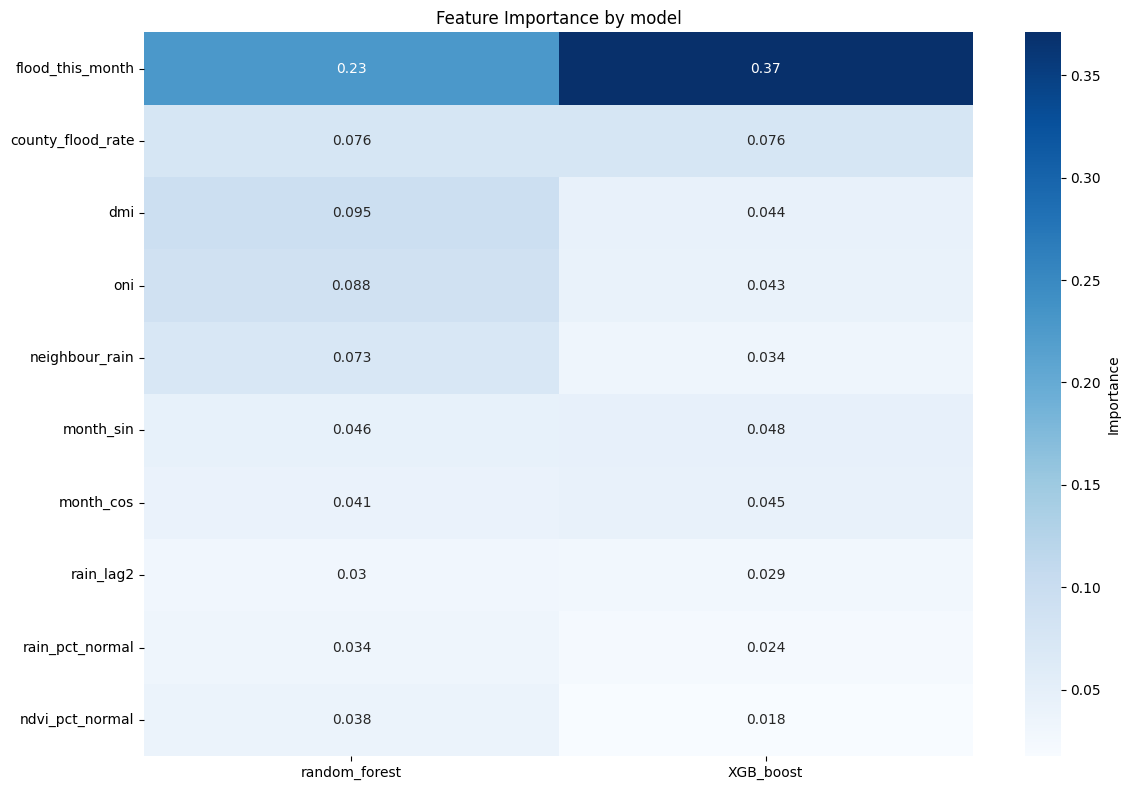

In [ ]:
top_features = 10
order = importances.mean(axis= 1).sort_values(ascending= False).head(top_features).index

plt.figure(figsize=(12, 8))
sns.heatmap(importances.loc[order], annot= True, cmap= "Blues", cbar_kws= {"label": "Importance"})
plt.title("Feature Importance by model")
plt.tight_layout()
plt.show()

## TAKEAWAYS

We introduced 2 autoregressive features that represent autodecent conditions. This correctly mirrors early warning flood systems, where current flood status is known before making a forecast. The models heavily prioritized 'flood_this_month', which doubled our PR_AUC and proved that historical flood state is a stronger predictor or flooding than weather anomalies alone.